# Fase 2 — Divisão dos Dados e Treinamento do Random Forest

**Projeto:** Redes Sociais vs Produtividade — Aprendizado de Máquina via Random Forest

Objetivos deste notebook:

1. Carregar o dataset processado na Fase 1 (`data/processed.csv`).
2. Separar os dados em **treino (80%)** e **teste (20%)**.
3. Instanciar e treinar um `RandomForestRegressor` com hiperparâmetros iniciais justificados.
4. Mostrar por que uma **floresta** generaliza melhor do que uma **árvore única**.
5. Salvar o modelo e os conjuntos de dados para as próximas fases.

> O conjunto de **teste não é usado em nenhum momento deste notebook**. Toda estimativa de desempenho aqui usa apenas o treino, por validação cruzada ou pelo erro *out-of-bag*. O teste fica reservado para a avaliação final na Fase 3.

## 1. Configuração do ambiente

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42
ALVO = "actual_productivity_score"
DATA_DIR = Path("data")
MODEL_DIR = Path("models")
FIG_DIR = Path("figures")
MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Mesma identidade visual da Fase 1
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "axes.edgecolor": INK_2, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "legend.frameon": False,
})


def salvar(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")


print(f"scikit-learn {sklearn.__version__}")

scikit-learn 1.9.1


## 2. Carregamento dos dados processados

In [2]:
df = pd.read_csv(DATA_DIR / "processed.csv")
X = df.drop(columns=[ALVO])
y = df[ALVO]
print(f"X: {X.shape[0]:,} linhas × {X.shape[1]} features   |   y: {ALVO}")
X.head()

X: 27,635 linhas × 28 features   |   y: actual_productivity_score


,age,daily_social_media_time,number_of_notifications,work_hours_per_day,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,uses_focus_apps,has_digital_wellbeing_enabled,...,job_Finance,job_Health,job_IT,job_Student,job_Unemployed,platform_Facebook,platform_Instagram,platform_Telegram,platform_TikTok,platform_Twitter
0,56,4.180940,61,6.753558,4.0,5.116546,0.419102,8,0,0,...,0,0,0,0,1,1,0,0,0,0
1,46,3.249603,59,9.169296,7.0,5.103897,0.671519,7,1,1,...,0,1,0,0,0,0,0,0,0,1
2,32,3.028026,57,7.910952,4.0,8.583222,0.624378,0,1,0,...,1,0,0,0,0,0,0,0,0,1
3,60,3.028026,59,6.355027,6.0,6.052984,1.204540,1,0,0,...,0,0,0,0,1,1,0,0,0,0
4,38,1.512568,50,6.429312,5.0,5.515251,1.518612,5,0,1,...,1,0,0,0,0,0,0,0,0,1


## 3. Divisão em treino e teste

- **80% treino / 20% teste:** com ~27 mil linhas, 20% (~5.500 pessoas) já é uma amostra grande o suficiente para estimar o erro com precisão, e o treino fica com a maior parte dos dados.
- **Estratificação pelo alvo:** `train_test_split` só estratifica variáveis categóricas, então dividimos o alvo contínuo em 10 faixas (decis) e estratificamos por elas. Assim, treino e teste têm a mesma proporção de pessoas pouco, medianamente e muito produtivas.
- **`random_state` fixo:** garante que a divisão seja reproduzível.

In [3]:
faixas_alvo = pd.qcut(y, q=10, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=faixas_alvo
)

print(f"Treino: {len(X_train):,} linhas ({len(X_train) / len(X):.0%})")
print(f"Teste:  {len(X_test):,} linhas ({len(X_test) / len(X):.0%})")
pd.DataFrame({"treino": y_train.describe(), "teste": y_test.describe()}).T

Treino: 22,108 linhas (80%)
Teste:  5,527 linhas (20%)


,count,mean,std,min,25%,50%,75%,max
treino,22108.0,4.950571,1.882811,0.296812,3.366862,4.951757,6.519766,9.846258
teste,5527.0,4.956739,1.885806,0.599785,3.398308,4.949933,6.570084,9.361366


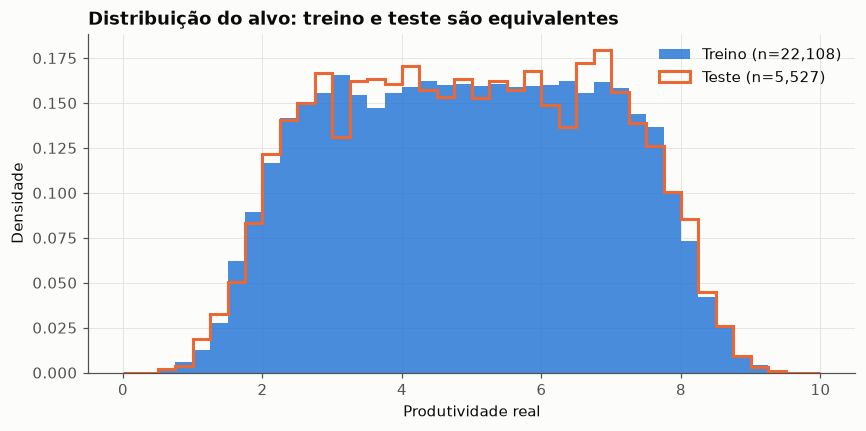

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 10, 41)
ax.hist(y_train, bins=bins, density=True, color=BLUE, alpha=0.85, label=f"Treino (n={len(y_train):,})")
ax.hist(y_test, bins=bins, density=True, histtype="step", color=ORANGE, lw=2, label=f"Teste (n={len(y_test):,})")
ax.set_xlabel("Produtividade real")
ax.set_ylabel("Densidade")
ax.set_title("Distribuição do alvo: treino e teste são equivalentes")
ax.legend()
salvar(fig, "02_split_treino_teste")
plt.show()

## 4. Escolha dos hiperparâmetros iniciais

| Hiperparâmetro | Valor | Justificativa |
|---|---|---|
| `n_estimators` | **300** | Número de árvores. Mais árvores reduzem a variância do consenso; a partir de algumas centenas o ganho estabiliza (verificado na Seção 6). |
| `max_features` | **0.5** | Cada divisão considera 50% das features sorteadas. O padrão clássico `sqrt` (5 de 28) faria muitas divisões **sem acesso** a `job_satisfaction_score`, a única variável com sinal forte (Fase 1), e as árvores gastariam divisões em ruído. Com 0.5 ainda há aleatoriedade suficiente para as árvores serem diferentes entre si. |
| `min_samples_leaf` | **10** | Cada folha precisa de pelo menos 10 pessoas. Evita que a árvore decore casos individuais, o que é importante porque a Fase 1 mostrou muito ruído no alvo. Também reduz bastante o tamanho do modelo salvo. |
| `max_depth` | `None` | A profundidade já fica controlada por `min_samples_leaf`. |
| `bootstrap` + `oob_score` | **True** | Cada árvore treina com uma amostra sorteada **com reposição**. As ~37% de linhas que ficam de fora de cada árvore (*out-of-bag*) funcionam como uma validação gratuita, sem tocar no teste. |
| `n_jobs` | **-1** | Treina as árvores em paralelo, usando todos os núcleos da CPU. |
| `random_state` | **42** | Reprodutibilidade. |

Estes valores são um **ponto de partida razoável**, e não o resultado de uma busca exaustiva. Na seção 7, uma comparação rápida (feita só com o OOB do treino) confirma que eles estão numa região boa.

In [5]:
PARAMS = dict(
    n_estimators=300,
    max_features=0.5,
    min_samples_leaf=10,
    max_depth=None,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
modelo = RandomForestRegressor(**PARAMS)
modelo

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.r2_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_

## 5. Treinamento

In [6]:
inicio = time.perf_counter()
modelo.fit(X_train, y_train)
tempo_treino = time.perf_counter() - inicio

r2_treino = modelo.score(X_train, y_train)
print(f"Tempo de treino: {tempo_treino:.1f} s  ({modelo.n_estimators} árvores)")
print(f"R² no próprio treino:   {r2_treino:.3f}  (otimista: o modelo já viu esses dados)")
print(f"R² out-of-bag (OOB):    {modelo.oob_score_:.3f}  (estimativa honesta de generalização)")

profundidades = [arvore.get_depth() for arvore in modelo.estimators_]
folhas = [arvore.get_n_leaves() for arvore in modelo.estimators_]
print(f"\nProfundidade das árvores: média {np.mean(profundidades):.1f} (mín {min(profundidades)}, máx {max(profundidades)})")
print(f"Folhas por árvore: média {np.mean(folhas):,.0f}")

Tempo de treino: 1.6 s  (300 árvores)
R² no próprio treino:   0.818  (otimista: o modelo já viu esses dados)
R² out-of-bag (OOB):    0.713  (estimativa honesta de generalização)

Profundidade das árvores: média 23.3 (mín 20, máx 33)
Folhas por árvore: média 1,090


A diferença entre o R² no treino e o R² OOB mostra quanto o modelo "decorou" dos dados de treino. O valor OOB é a referência realista, e deve ficar próximo do resultado no teste (Fase 3).

## 6. Por que uma floresta? Árvore única vs Random Forest

Uma árvore de decisão sozinha tende a **decorar** o treino: ela cresce até isolar cada pessoa numa folha. Abaixo, comparamos com **validação cruzada (5 folds) no treino**:

- uma árvore única sem restrições;
- uma árvore única com a mesma regularização da floresta (`min_samples_leaf=10`);
- a Random Forest.

In [7]:
candidatos = {
    "Árvore única (sem limite)": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Árvore única (min_samples_leaf=10)": DecisionTreeRegressor(min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest (300 árvores)": RandomForestRegressor(**{**PARAMS, "oob_score": False}),
}

comparacao = []
for nome, est in candidatos.items():
    cv = cross_val_score(est, X_train, y_train, cv=5, scoring="r2", n_jobs=1 if "Forest" in nome else -1)
    r2_fit = est.fit(X_train, y_train).score(X_train, y_train)
    comparacao.append({"modelo": nome, "R² treino": r2_fit, "R² validação (CV)": cv.mean(), "desvio CV": cv.std()})

comparacao = pd.DataFrame(comparacao).set_index("modelo")
comparacao["gap (overfitting)"] = comparacao["R² treino"] - comparacao["R² validação (CV)"]
comparacao.round(3)

,R² treino,R² validação (CV),desvio CV,gap (overfitting)
modelo,,,,
Árvore única (sem limite),1.000,0.408,0.018,0.592
Árvore única (min_samples_leaf=10),0.827,0.605,0.010,0.222
Random Forest (300 árvores),0.818,0.714,0.005,0.104


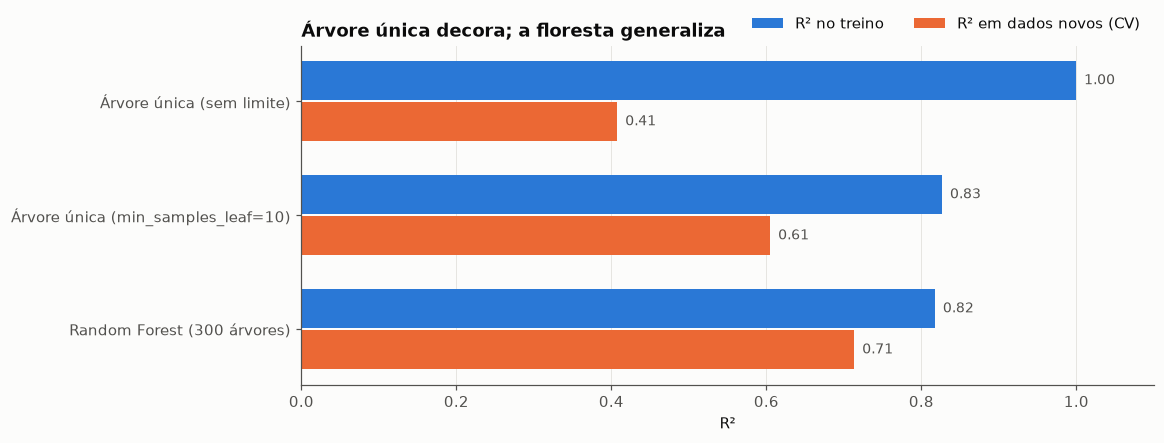

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ypos = np.arange(len(comparacao))
ax.barh(ypos - 0.18, comparacao["R² treino"], height=0.34, color=BLUE, label="R² no treino")
ax.barh(ypos + 0.18, comparacao["R² validação (CV)"], height=0.34, color=ORANGE, label="R² em dados novos (CV)")
for i, (tr, va) in enumerate(zip(comparacao["R² treino"], comparacao["R² validação (CV)"])):
    ax.text(tr + 0.01, i - 0.18, f"{tr:.2f}", va="center", fontsize=9, color=INK_2)
    ax.text(va + 0.01, i + 0.18, f"{va:.2f}", va="center", fontsize=9, color=INK_2)
ax.set_yticks(ypos, comparacao.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.1)
ax.set_xlabel("R²")
ax.set_title("Árvore única decora; a floresta generaliza")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.grid(axis="y", visible=False)
salvar(fig, "02_arvore_vs_floresta")
plt.show()

**Leitura:** a árvore sem limite acerta 100% do treino (R² = 1), mas despenca em dados novos. É o retrato do **overfitting**. Regularizar a árvore ajuda, mas a floresta ainda vai além: cada árvore erra de um jeito diferente, porque viu amostras e features diferentes, e a **média** das 300 previsões cancela boa parte desses erros individuais. Esse é o princípio do *bagging*, ou "sabedoria das multidões".

### 6.1 Quantas árvores são suficientes?

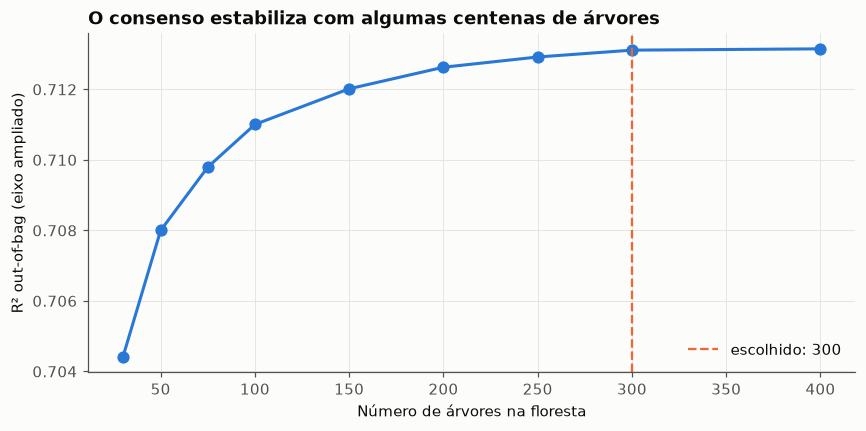

árvores,30,50,75,100,150,200,250,300,400
R² OOB,0.7044,0.708,0.7098,0.711,0.712,0.7126,0.7129,0.7131,0.7131


In [9]:
# warm_start=True adiciona árvores sem retreinar as anteriores; medimos o R² OOB a cada etapa.
# Começamos em 30: com menos árvores, algumas linhas caem no bootstrap de todas elas e ficam sem previsão OOB.
curva = RandomForestRegressor(**{**PARAMS, "n_estimators": 30, "warm_start": True})
n_arvores = [30, 50, 75, 100, 150, 200, 250, 300, 400]
oob_por_n = []
for n in n_arvores:
    curva.set_params(n_estimators=n)
    curva.fit(X_train, y_train)
    oob_por_n.append(curva.oob_score_)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(n_arvores, oob_por_n, "o-", color=BLUE, lw=2, ms=7)
ax.axvline(PARAMS["n_estimators"], color=ORANGE, ls="--", lw=1.5, label=f"escolhido: {PARAMS['n_estimators']}")
ax.set_xlabel("Número de árvores na floresta")
ax.set_ylabel("R² out-of-bag (eixo ampliado)")
ax.set_title("O consenso estabiliza com algumas centenas de árvores")
ax.legend(loc="lower right")
salvar(fig, "02_oob_vs_n_arvores")
plt.show()
pd.Series(oob_por_n, index=pd.Index(n_arvores, name="árvores"), name="R² OOB").round(4).to_frame().T

## 7. Sanidade dos hiperparâmetros (sem tocar no teste)

Uma comparação rápida, só com o R² OOB, de algumas combinações de `max_features` e `min_samples_leaf`. O objetivo é confirmar que os valores escolhidos estão numa região boa. O ajuste fino fica fora do escopo desta fase.

In [10]:
grade = []
for mf in ["sqrt", 0.5, 1.0]:
    for leaf in [1, 10, 30]:
        rf = RandomForestRegressor(**{**PARAMS, "n_estimators": 150, "max_features": mf, "min_samples_leaf": leaf})
        rf.fit(X_train, y_train)
        grade.append({"max_features": str(mf), "min_samples_leaf": leaf, "R² OOB": rf.oob_score_})

grade = pd.DataFrame(grade).pivot(index="max_features", columns="min_samples_leaf", values="R² OOB")
grade.round(4)

min_samples_leaf,1,10,30
max_features,,,
0.5,0.7068,0.7120,0.7136
1.0,0.7038,0.7099,0.7131
sqrt,0.6930,0.6895,0.6736


**Leitura:** `max_features="sqrt"` fica sistematicamente abaixo, porque muitas divisões não têm acesso à variável dominante, como previsto na Seção 4. Com `max_features` 0.5 ou 1.0, folhas maiores (`min_samples_leaf` ≥ 10) generalizam melhor do que árvores totalmente crescidas, já que o alvo tem muito ruído. Com `sqrt` acontece o contrário: as árvores já são fracas por raramente verem a variável dominante, e limitar as folhas as deixa fracas demais (*underfitting*). Entre 10 e 30 a diferença é de apenas ~0,002, então a configuração escolhida (0.5, 10) é adequada como ponto de partida.

## 8. Salvando o modelo e os conjuntos de dados

In [11]:
caminho_modelo = MODEL_DIR / "random_forest.joblib"
joblib.dump(modelo, caminho_modelo, compress=3)

X_train.assign(**{ALVO: y_train}).to_csv(DATA_DIR / "train.csv", index=False)
X_test.assign(**{ALVO: y_test}).to_csv(DATA_DIR / "test.csv", index=False)

metadados = {
    "alvo": ALVO,
    "features": X.columns.tolist(),
    "hiperparametros": {k: v for k, v in PARAMS.items() if k != "n_jobs"},
    "n_treino": len(X_train),
    "n_teste": len(X_test),
    "r2_treino": round(r2_treino, 4),
    "r2_oob": round(modelo.oob_score_, 4),
    "tempo_treino_s": round(tempo_treino, 2),
    "versao_sklearn": sklearn.__version__,
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadados, indent=2, ensure_ascii=False))

print(f"Modelo:     {caminho_modelo}  ({caminho_modelo.stat().st_size / 1e6:.1f} MB)")
print(f"Metadados:  {MODEL_DIR / 'metadata.json'}")
print(f"Treino:     {DATA_DIR / 'train.csv'}")
print(f"Teste:      {DATA_DIR / 'test.csv'}")

Modelo:     models/random_forest.joblib  (17.0 MB)
Metadados:  models/metadata.json
Treino:     data/train.csv
Teste:      data/test.csv


In [12]:
# Verificação: o modelo recarregado faz exatamente as mesmas previsões
recarregado = joblib.load(caminho_modelo)
assert np.allclose(recarregado.predict(X_train.head(100)), modelo.predict(X_train.head(100)))
print("Modelo recarregado com sucesso.")

Modelo recarregado com sucesso.


## 9. Resumo e próximos passos

| Item | Valor |
|---|---|
| Divisão | 80% treino / 20% teste, estratificada por decis do alvo |
| Modelo | `RandomForestRegressor` com 300 árvores, `max_features=0.5`, `min_samples_leaf=10` |
| Estimativa de generalização | R² OOB calculado na Seção 5 |
| Artefatos | `models/random_forest.joblib`, `models/metadata.json`, `data/train.csv`, `data/test.csv` |

**Fase 3:** carregar o modelo, fazer previsões no conjunto de **teste** e calcular RMSE, MAE e R², com gráficos de previsão vs realidade.